# Day 98 — Perceptron Trick | How to Train a Perceptron | Perceptron Part 2

In this notebook we will:
1. Visualize **one perceptron-trick update** (the line moves toward a misclassified point)
2. Implement the **full perceptron trick** and track mistakes
3. Study the **effect of the learning rate**
4. Show the **unified update rule** (0/1 labels vs +1/-1 labels)
5. Train with the **perceptron loss + gradient descent** and verify the gradient
6. See what happens on **non-separable data**, and the **pocket** idea
7. Look at the **no-margin** problem (teaser for SVM)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

np.random.seed(42)

## 0. Data and helpers

We fold the bias into the weights: add a column of ones to X, so `w = [b, w1, w2]` and the score is simply `w · x_aug`.

In [2]:
X, y = make_blobs(n_samples=100, centers=[[0, 0], [4, 4]], cluster_std=1.0, random_state=1)

def add_bias(X):
    return np.c_[np.ones(len(X)), X]          # x_aug = [1, x1, x2]

Xb = add_bias(X)

def predict(w, Xb):
    return (Xb @ w >= 0).astype(int)

def n_mistakes(w, Xb, y):
    return int((predict(w, Xb) != y).sum())

def line_points(w, x_vals):
    # w = [b, w1, w2]; boundary: b + w1*x1 + w2*x2 = 0
    return -(w[0] + w[1] * x_vals) / w[2]

def draw(ax, w, Xb, y, title, highlight=None, color="g", label=None):
    ax.scatter(Xb[:, 1], Xb[:, 2], c=y, cmap="coolwarm", edgecolor="k", alpha=0.8)
    xs = np.linspace(Xb[:, 1].min() - 1, Xb[:, 1].max() + 1, 100)
    if abs(w[2]) > 1e-9:
        ax.plot(xs, line_points(w, xs), color=color, lw=2, label=label)
    if highlight is not None:
        ax.scatter(*Xb[highlight, 1:], s=250, facecolors="none", edgecolors="black", lw=2)
    ax.set_xlim(Xb[:, 1].min() - 1, Xb[:, 1].max() + 1)
    ax.set_ylim(Xb[:, 2].min() - 1, Xb[:, 2].max() + 1)
    ax.set_title(title)

## 1. The Perceptron Trick: one update, geometrically

For a **misclassified** point `x`:

| Situation | Update |
|---|---|
| True class 1 but predicted 0 (point is on the negative side) | `w ← w + η·x` |
| True class 0 but predicted 1 (point is on the positive side) | `w ← w − η·x` |

Adding (or subtracting) the point to the weight vector rotates and shifts the line toward correctly classifying it.

Misclassified point index 0: x = [-0.53 -1.07], true class = 0, predicted = 1
w before: [ 0.  1. -1.] | mistakes: 43
w after : [-0.5    1.264 -0.464] | mistakes: 18


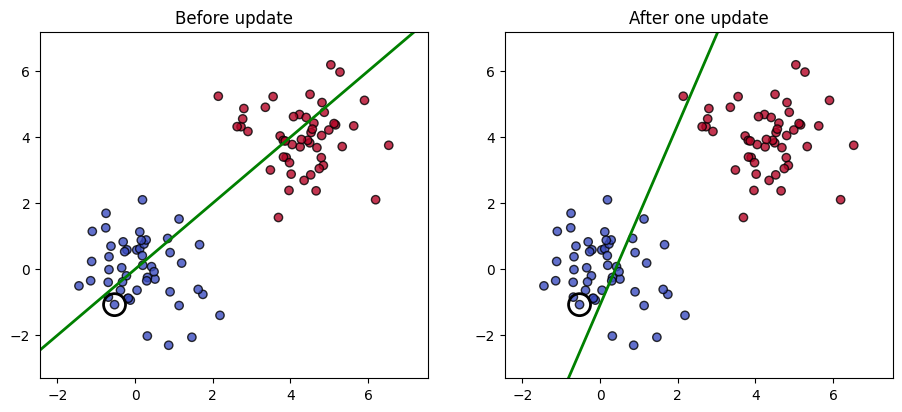

In [3]:
w = np.array([0.0, 1.0, -1.0])                    # a deliberately poor starting line
lr = 0.5

wrong = np.where(predict(w, Xb) != y)[0]
i = wrong[0]
print(f"Misclassified point index {i}: x = {X[i].round(2)}, true class = {y[i]}, predicted = {predict(w, Xb)[i]}")

w_new = w + lr * (y[i] - predict(w, Xb)[i]) * Xb[i]
print("w before:", w, "| mistakes:", n_mistakes(w, Xb, y))
print("w after :", w_new.round(3), "| mistakes:", n_mistakes(w_new, Xb, y))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
draw(axes[0], w, Xb, y, "Before update", highlight=i)
draw(axes[1], w_new, Xb, y, "After one update", highlight=i)
plt.show()

## 2. Full Perceptron Trick algorithm

```
repeat:
    pick a random point
    if it is misclassified: update w
until no mistakes (or max iterations)
```

Iterations: 77 | updates made: 11
Final w = [-0.9    0.22   0.228] | mistakes: 0


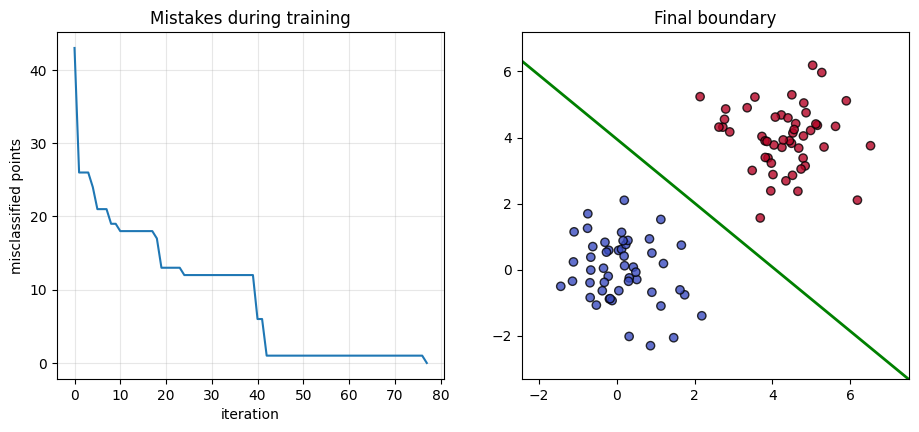

In [4]:
def perceptron_trick(Xb, y, lr=0.1, max_iter=1000, seed=0, w0=None):
    rng = np.random.RandomState(seed)
    w = np.zeros(Xb.shape[1]) if w0 is None else w0.copy()
    mistakes_log = [n_mistakes(w, Xb, y)]
    updates = 0
    for _ in range(max_iter):
        j = rng.randint(len(Xb))                       # random point
        y_hat = int(Xb[j] @ w >= 0)
        if y_hat != y[j]:
            w = w + lr * (y[j] - y_hat) * Xb[j]        # +x or -x (scaled by lr)
            updates += 1
        mistakes_log.append(n_mistakes(w, Xb, y))
        if mistakes_log[-1] == 0:
            break
    return w, mistakes_log, updates

w_final, log, updates = perceptron_trick(Xb, y, lr=0.1, w0=np.array([0.0, 1.0, -1.0]))
print("Iterations:", len(log) - 1, "| updates made:", updates)
print("Final w =", w_final.round(3), "| mistakes:", n_mistakes(w_final, Xb, y))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(log); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("misclassified points")
axes[0].set_title("Mistakes during training"); axes[0].grid(alpha=0.3)
draw(axes[1], w_final, Xb, y, "Final boundary")
plt.show()

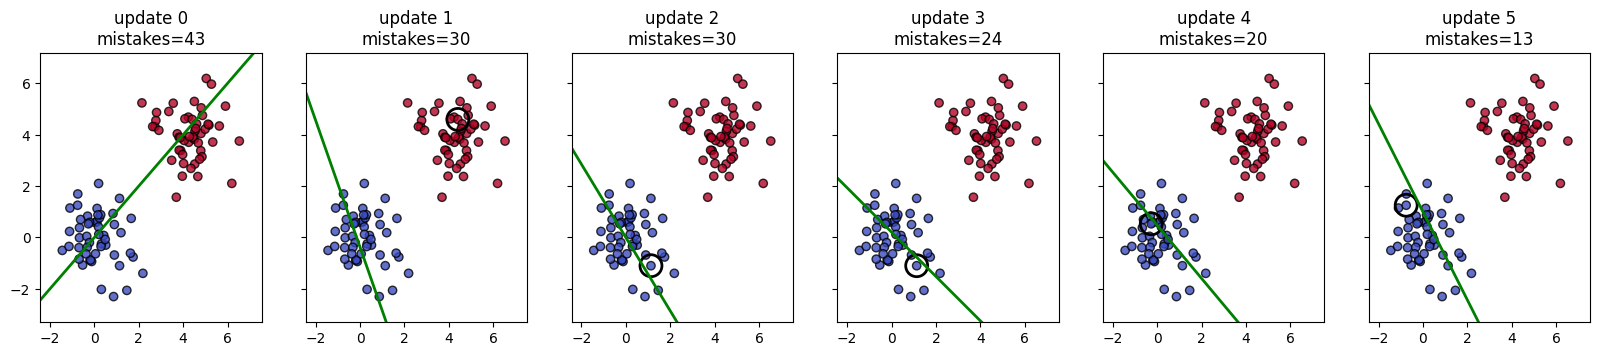

In [5]:
# Step-by-step view of the first few updates
w = np.array([0.0, 1.0, -1.0]); rng = np.random.RandomState(0)
snapshots = [(w.copy(), None)]
while len(snapshots) < 6:
    j = rng.randint(len(Xb)); y_hat = int(Xb[j] @ w >= 0)
    if y_hat != y[j]:
        w = w + 0.5 * (y[j] - y_hat) * Xb[j]
        snapshots.append((w.copy(), j))

fig, axes = plt.subplots(1, 6, figsize=(20, 3.5), sharey=True)
for k, (ax, (wk, jk)) in enumerate(zip(axes, snapshots)):
    draw(ax, wk, Xb, y, f"update {k}\nmistakes={n_mistakes(wk, Xb, y)}", highlight=jk)
plt.show()

## 3. Effect of the learning rate

With the weights **starting at zero**, the learning rate only scales `w`, so the final *decision boundary* is the same;
it matters when you start from a non-zero `w` (the update size is compared with the existing weights).

In [6]:
w0 = np.array([0.0, 1.0, -1.0])
print(f"{'lr':>6} | {'updates':>8} | {'iterations':>10} | final mistakes")
for lr in [0.01, 0.1, 1.0, 10.0]:
    wf, lg, upd = perceptron_trick(Xb, y, lr=lr, w0=w0, max_iter=5000)
    print(f"{lr:6.2f} | {upd:8d} | {len(lg)-1:10d} | {lg[-1]}")

print()
print("From zero initial weights:")
for lr in [0.01, 1.0, 100.0]:
    wf, lg, upd = perceptron_trick(Xb, y, lr=lr, max_iter=5000)
    print(f"lr={lr:6.2f} -> w direction (normalized) = {(wf / np.linalg.norm(wf)).round(4)}, updates = {upd}")

    lr |  updates | iterations | final mistakes
  0.01 |       99 |       1513 | 0
  0.10 |       11 |         77 | 0
  1.00 |        8 |         40 | 0
 10.00 |       15 |        198 | 0

From zero initial weights:
lr=  0.01 -> w direction (normalized) = [-0.9395  0.3266  0.1032], updates = 10
lr=  1.00 -> w direction (normalized) = [-0.9395  0.3266  0.1032], updates = 10
lr=100.00 -> w direction (normalized) = [-0.9395  0.3266  0.1032], updates = 10


## 4. A unified update rule

With 0/1 labels the error `(y − ŷ)` is `+1`, `−1` or `0`, so both cases collapse into one line:

`w ← w + η · (y − ŷ) · x`

The same rule with **±1 labels** (`t = 2y − 1`) is `w ← w + η · t · x` for misclassified points only.

In [7]:
rng = np.random.RandomState(3)
agree = True
for _ in range(1000):
    xj = Xb[rng.randint(len(Xb))]
    wj = rng.randn(3)
    yj = rng.randint(2)
    # 0/1 form
    y_hat = int(xj @ wj >= 0)
    w01 = wj + 0.1 * (yj - y_hat) * xj
    # +-1 form (update only if misclassified): equals the 0/1 rule
    t = 2 * yj - 1
    s = 1 if xj @ wj >= 0 else -1
    wpm = wj + 0.1 * t * xj if s != t else wj
    agree &= np.allclose(w01, wpm)
print("0/1 rule and +-1 rule agree on 1000 random cases:", agree)

0/1 rule and +-1 rule agree on 1000 random cases: True


## 5. Perceptron Part 2: training with a loss function

The trick is a heuristic. A cleaner view: define a **loss** and run **gradient descent**.

With labels `t ∈ {−1, +1}` and score `s = w · x`:

`L(w) = (1/n) · Σ max(0, −t_i · s_i)`

- Correctly classified point (`t·s > 0`) → loss **0**
- Misclassified point → loss is the **distance-like penalty** `−t·s`

Gradient for a misclassified point: `∂L/∂w = −t · x`, so gradient descent gives `w ← w + η · t · x`, exactly the perceptron trick.

In [8]:
t = 2 * y - 1                                     # labels in {-1, +1}

def perceptron_loss(w, Xb, t):
    return np.mean(np.maximum(0, -t * (Xb @ w)))

def perceptron_grad(w, Xb, t):
    mis = (t * (Xb @ w)) <= 0                    # misclassified (or on the boundary)
    return -(t[mis, None] * Xb[mis]).sum(axis=0) / len(Xb)

# numerical gradient check (finite differences)
w_test = np.array([0.3, -0.5, 0.8])
num = np.zeros(3); eps = 1e-6
for k in range(3):
    d = np.zeros(3); d[k] = eps
    num[k] = (perceptron_loss(w_test + d, Xb, t) - perceptron_loss(w_test - d, Xb, t)) / (2 * eps)
print("Analytic gradient:", perceptron_grad(w_test, Xb, t).round(5))
print("Numeric  gradient:", num.round(5))

Analytic gradient: [ 0.27    -0.1868   0.10754]
Numeric  gradient: [ 0.27    -0.1868   0.10754]


Final loss: 0.0 | final mistakes: 0


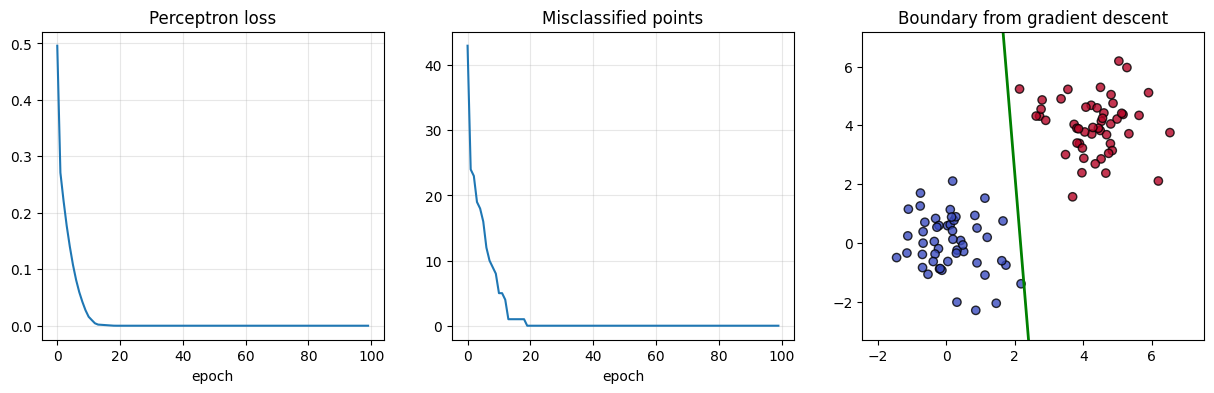

In [9]:
def train_gd(Xb, t, lr=0.1, epochs=200, w0=None):
    w = np.zeros(Xb.shape[1]) if w0 is None else w0.copy()
    losses, mistakes = [], []
    for _ in range(epochs):
        losses.append(perceptron_loss(w, Xb, t))
        mistakes.append(n_mistakes(w, Xb, y))
        w = w - lr * perceptron_grad(w, Xb, t)
    return w, losses, mistakes

w_gd, losses, mistakes = train_gd(Xb, t, lr=0.5, epochs=100, w0=np.array([0.0, 1.0, -1.0]))
print("Final loss:", round(losses[-1], 4), "| final mistakes:", mistakes[-1])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(losses); axes[0].set_title("Perceptron loss"); axes[0].set_xlabel("epoch"); axes[0].grid(alpha=0.3)
axes[1].plot(mistakes); axes[1].set_title("Misclassified points"); axes[1].set_xlabel("epoch"); axes[1].grid(alpha=0.3)
draw(axes[2], w_gd, Xb, y, "Boundary from gradient descent")
plt.show()

## 6. Non-separable data: the trick never settles

If the classes overlap, there is always at least one mistake, so the updates never stop.

Mistakes per epoch (first 20): [20, 19, 20, 17, 21, 19, 19, 19, 21, 23, 15, 21, 20, 21, 20, 25, 21, 25, 43, 17]
Best epoch had 15 mistakes, last epoch had 19


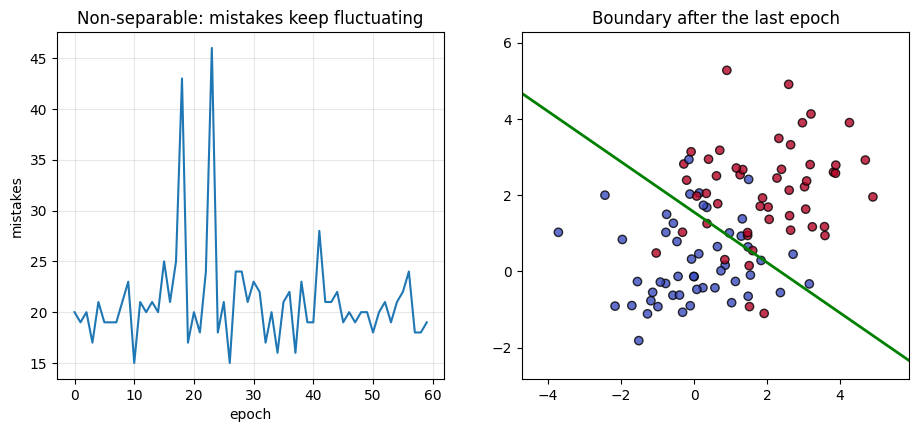

In [10]:
Xo, yo = make_blobs(n_samples=100, centers=[[0, 0], [2, 2]], cluster_std=1.3, random_state=5)
Xob = add_bias(Xo)

def run_epochs(Xb, y, lr=0.1, epochs=60, seed=0):
    rng = np.random.RandomState(seed)
    w = np.zeros(Xb.shape[1])
    log = []
    for _ in range(epochs):
        for j in rng.permutation(len(Xb)):
            y_hat = int(Xb[j] @ w >= 0)
            w = w + lr * (y[j] - y_hat) * Xb[j]
        log.append(n_mistakes(w, Xb, y))
    return w, log

w_ns, log_ns = run_epochs(Xob, yo)
print("Mistakes per epoch (first 20):", log_ns[:20])
print("Best epoch had", min(log_ns), "mistakes, last epoch had", log_ns[-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(log_ns); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mistakes")
axes[0].set_title("Non-separable: mistakes keep fluctuating"); axes[0].grid(alpha=0.3)
draw(axes[1], w_ns, Xob, yo, "Boundary after the last epoch")
plt.show()

### Pocket algorithm (simple fix)

Keep a copy of the **best weights seen so far** ("in your pocket") and return those at the end.

In [11]:
def pocket(Xb, y, lr=0.1, epochs=60, seed=0):
    rng = np.random.RandomState(seed)
    w = np.zeros(Xb.shape[1])
    best_w, best_m = w.copy(), n_mistakes(w, Xb, y)
    for _ in range(epochs):
        for j in rng.permutation(len(Xb)):
            y_hat = int(Xb[j] @ w >= 0)
            if y_hat != y[j]:
                w = w + lr * (y[j] - y_hat) * Xb[j]
                m = n_mistakes(w, Xb, y)
                if m < best_m:
                    best_w, best_m = w.copy(), m
    return best_w, best_m

w_pocket, m_pocket = pocket(Xob, yo)
print("Plain perceptron (last epoch) mistakes:", log_ns[-1])
print("Pocket algorithm mistakes             :", m_pocket)

Plain perceptron (last epoch) mistakes: 19
Pocket algorithm mistakes             : 14


## 7. The perceptron finds *a* boundary, not the *best* boundary

The trick stops as soon as every point is correct, so the line can sit very close to some points (small **margin**).
A linear SVM looks for the line with the **largest margin**.

Perceptron smallest distance to boundary: 0.852
Linear SVM smallest distance to boundary: 1.095


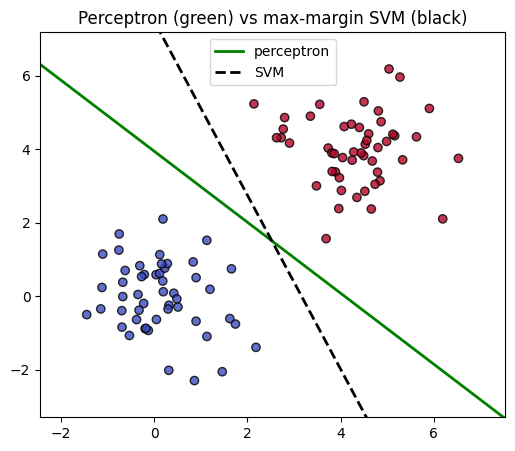

In [12]:
svm = SVC(kernel="linear", C=1e3).fit(X, y)
w_svm = np.r_[svm.intercept_, svm.coef_[0]]

def margin(w, Xb, y):
    s = (Xb @ w) / np.linalg.norm(w[1:])            # signed distance to the line
    t_ = 2 * y - 1
    return (t_ * s).min()

w_p, _, _ = perceptron_trick(Xb, y, lr=0.1, w0=np.array([0.0, 1.0, -1.0]))
print(f"Perceptron smallest distance to boundary: {margin(w_p, Xb, y):.3f}")
print(f"Linear SVM smallest distance to boundary: {margin(w_svm, Xb, y):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
draw(ax, w_p, Xb, y, "Perceptron (green) vs max-margin SVM (black)", label="perceptron")
xs = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
ax.plot(xs, line_points(w_svm, xs), "k--", lw=2, label="SVM")
ax.legend(); plt.show()

## Summary

- **Perceptron trick:** pick a point; if misclassified, add (class 1) or subtract (class 0) it from `w` (scaled by η)
- **Unified rule:** `w ← w + η(y − ŷ)x`
- **Loss view:** perceptron loss `max(0, −t·s)`, whose gradient descent gives the same update
- Converges **only** if the data is linearly separable; otherwise use the **pocket** idea or a smoother model
- It finds *a* separating line, not the **max-margin** one (idea behind SVM)
- Hard 0/1 output and no probabilities lead to **logistic regression** (sigmoid + log loss) next

## Practice exercises

1. Run the trick with 3 different random seeds and compare how many updates each needs.
2. Change `make_blobs` centers to `[[0, 0], [2, 2]]` with `cluster_std=0.5`. How do updates change as the margin shrinks?
3. Implement mini-batch gradient descent for the perceptron loss and compare it with the full-batch version.
4. Replace the perceptron loss with a **squared hinge** `max(0, 1 − t·s)²` and see how the boundary changes.
5. Apply the pocket algorithm to `make_moons` data. How good can a linear boundary get?